In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.model_selection import GridSearchCV

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


import joblib

In [ ]:
df = pd.read_csv("/content/used_phone_price_prediction_1M.csv")

In [ ]:
df.head()

,brand,model,release_year,ram_gb,storage_gb,screen_size_inches,battery_capacity,processor_score,camera_score,os_type,...,body_damage,repair_history,water_damage,city_tier,seller_type,warranty_remaining_months,box_available,charger_available,market_demand_score,resale_price
0,Realme,Realme GT,2025,4,256,6.93,4130,47,100,Android,...,0,0,0,Tier1,Individual,11,1,1,99,47891.46
1,Samsung,Galaxy S21,2024,16,64,6.29,5558,81,67,Android,...,0,0,0,Tier3,Store,8,1,0,64,17663.21
2,Apple,iPhone 11,2022,4,128,5.52,5945,59,67,iOS,...,0,0,0,Tier1,Individual,0,0,1,68,67268.20
3,Google,Pixel 6,2024,16,512,5.99,5767,84,57,Android,...,0,0,1,Tier1,Store,11,1,1,50,12626.26
4,Google,Pixel 7,2021,4,128,6.59,5336,98,44,Android,...,0,0,0,Tier3,Store,24,1,1,66,20662.25


In [ ]:


df.shape

df.info()

df.describe()

df.describe(include='object')

df.isnull().sum()

df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   brand                      1000000 non-null  object 
 1   model                      1000000 non-null  object 
 2   release_year               1000000 non-null  int64  
 3   ram_gb                     1000000 non-null  int64  
 4   storage_gb                 1000000 non-null  int64  
 5   screen_size_inches         1000000 non-null  float64
 6   battery_capacity           1000000 non-null  int64  
 7   processor_score            1000000 non-null  int64  
 8   camera_score               1000000 non-null  int64  
 9   os_type                    1000000 non-null  object 
 10  has_5g                     1000000 non-null  int64  
 11  original_price             1000000 non-null  int64  
 12  purchase_year              1000000 non-null  int64  
 13  age_months   

np.int64(0)

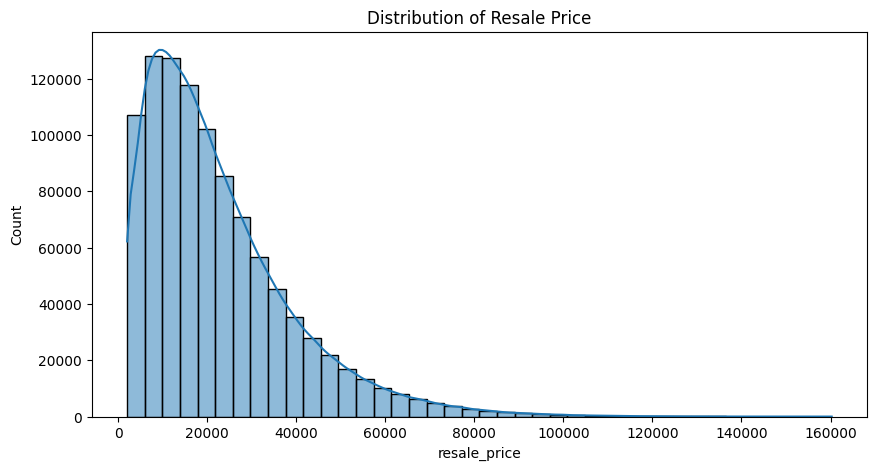

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df["resale_price"], bins=40, kde=True)
plt.title("Distribution of Resale Price")
plt.show()

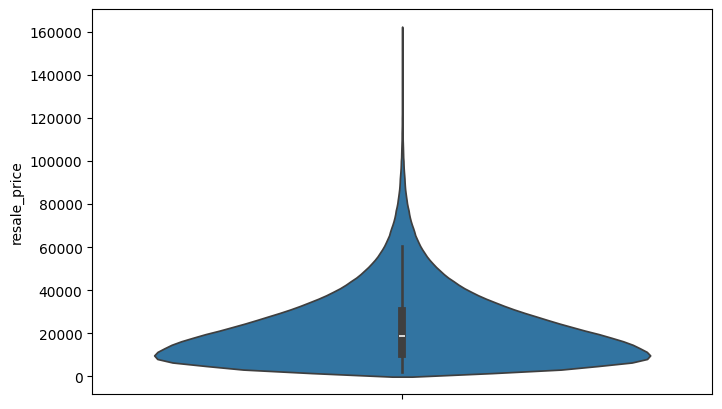

In [ ]:
plt.figure(figsize=(8,5))
sns.violinplot(y=df["resale_price"])
plt.show()

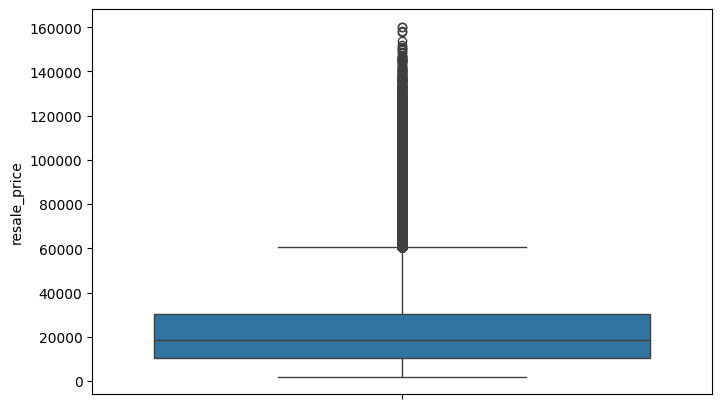

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(y=df["resale_price"])
plt.show()

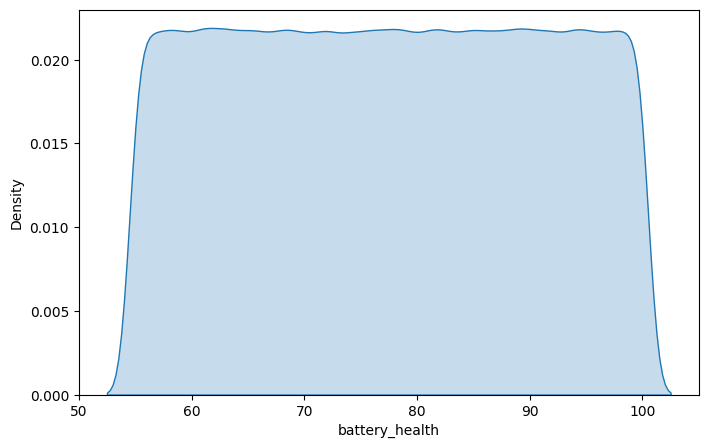

In [ ]:
plt.figure(figsize=(8,5))
sns.kdeplot(df["battery_health"], fill=True)
plt.show()

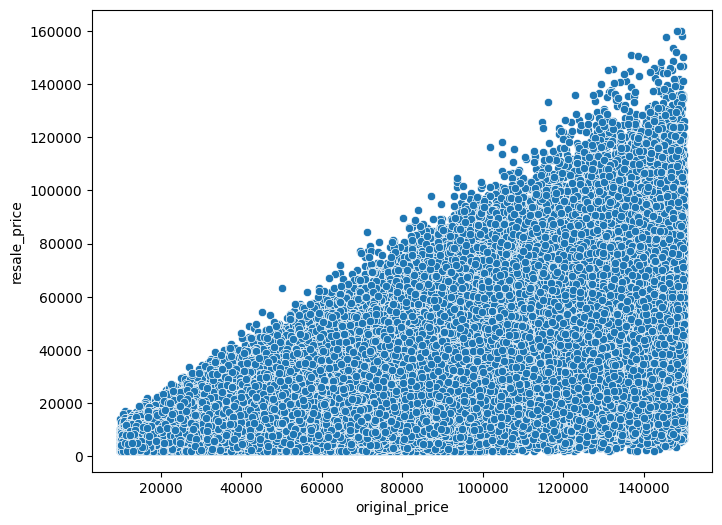

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    x="original_price",
    y="resale_price",
    data=df
)
plt.show()

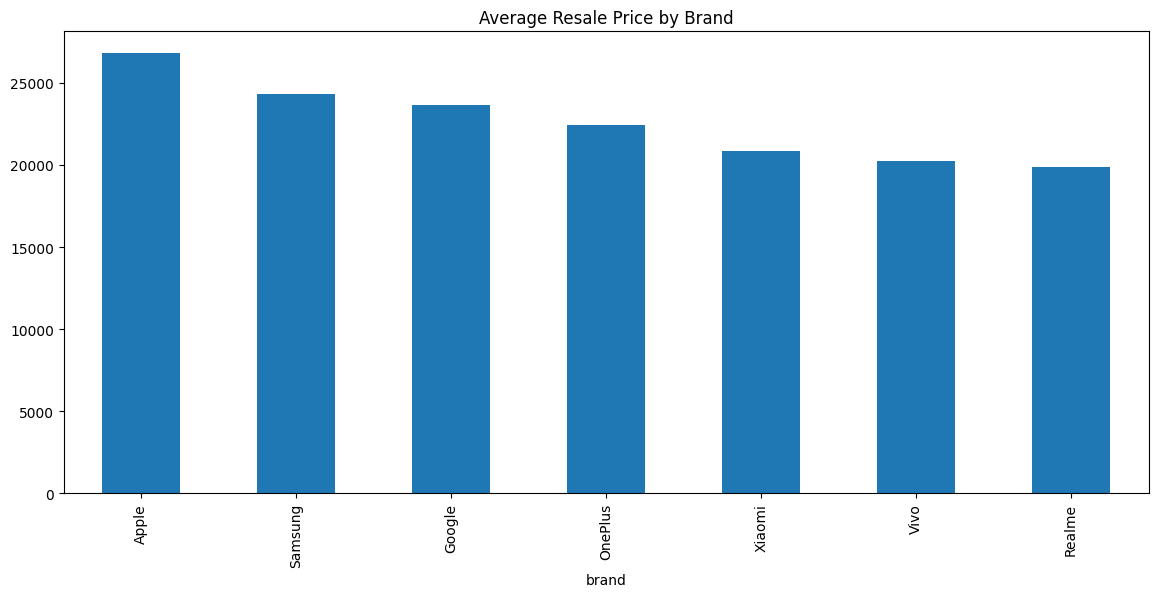

In [ ]:
plt.figure(figsize=(14,6))

df.groupby("brand")["resale_price"]\
.mean()\
.sort_values(ascending=False)\
.head(10)\
.plot(kind="bar")

plt.title("Average Resale Price by Brand")

plt.show()

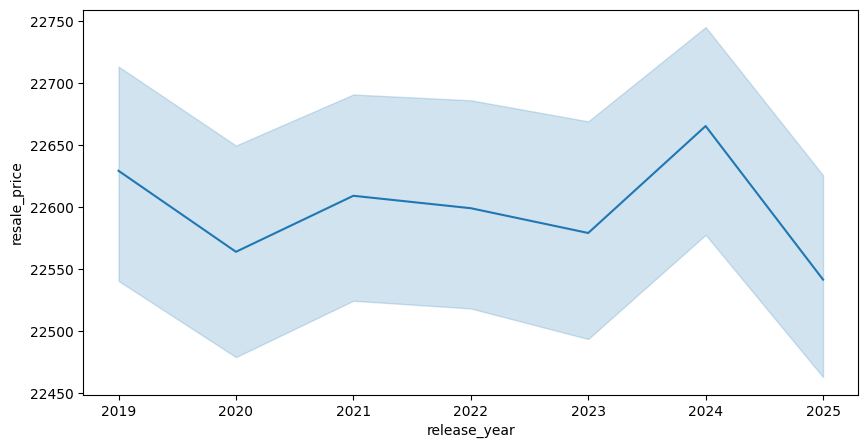

In [ ]:
plt.figure(figsize=(10,5))
sns.lineplot(
    x="release_year",
    y="resale_price",
    data=df
)
plt.show()

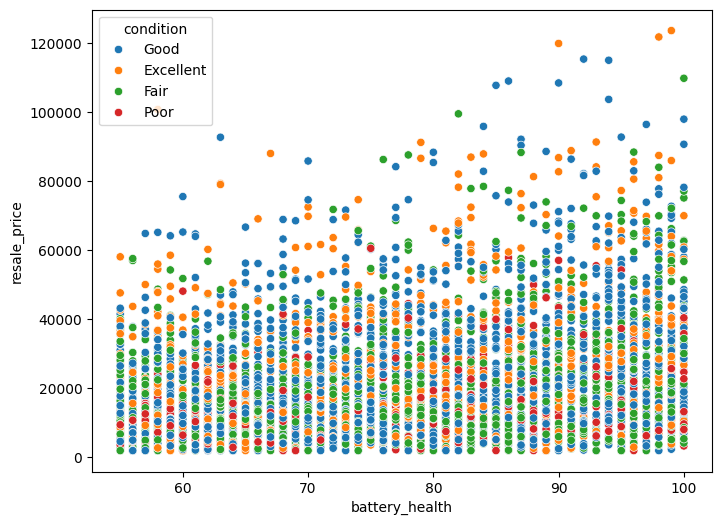

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x="battery_health",
    y="resale_price",
    hue="condition",
    data=df.sample(5000)
)

plt.show()

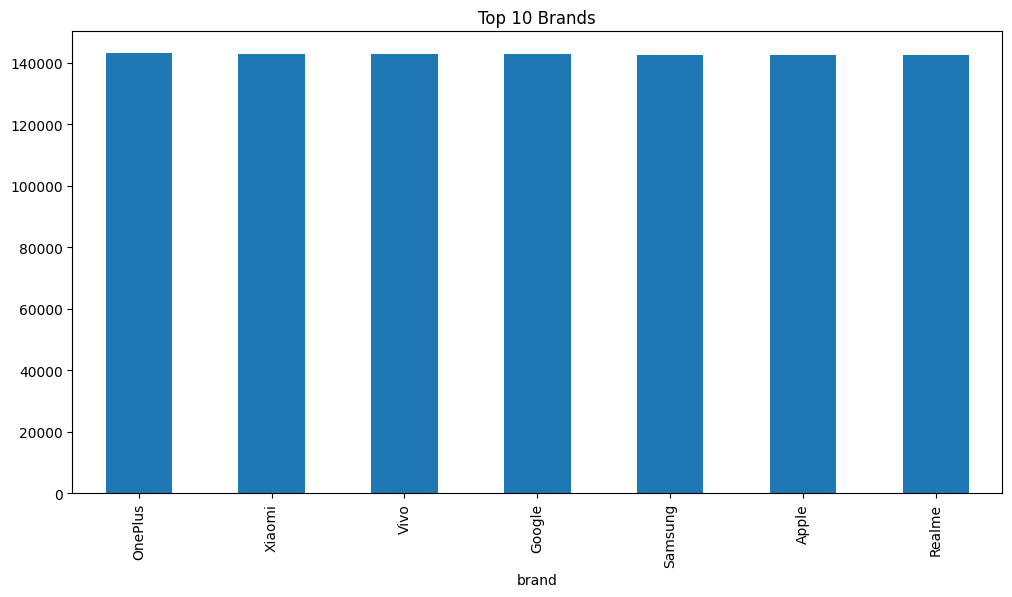

In [ ]:
plt.figure(figsize=(12,6))

df["brand"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Brands")

plt.show()

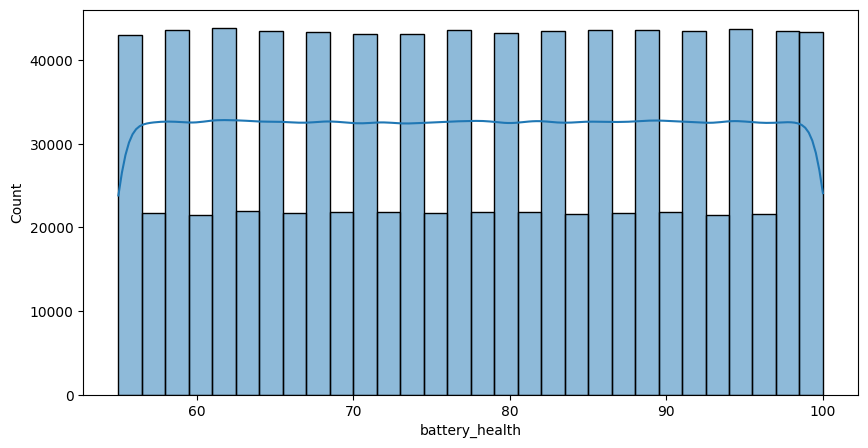

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["battery_health"],
    kde=True,
    bins=30
)

plt.show()

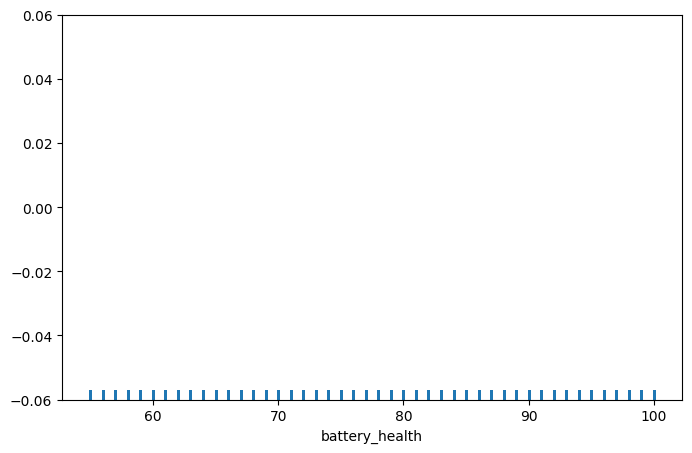

In [ ]:
plt.figure(figsize=(8,5))

sns.rugplot(df["battery_health"])

plt.show()

In [ ]:
df["phone_age"] = 2026 - df["release_year"]

df["price_per_gb"] = df["original_price"] / df["storage_gb"]

df["battery_ratio"] = df["battery_health"] / 100

In [ ]:
le = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

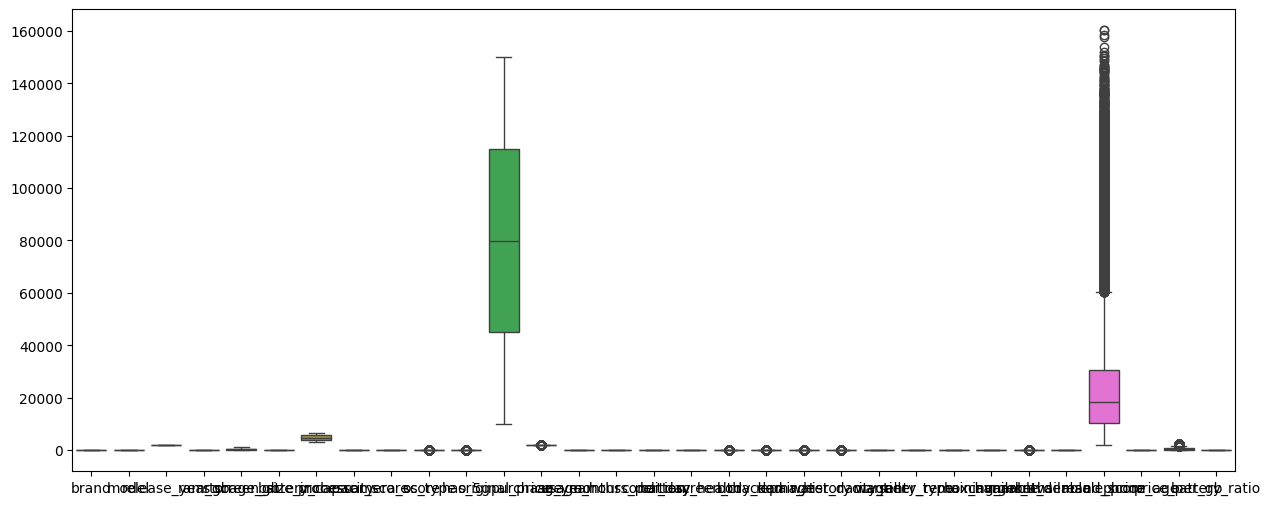

In [ ]:
plt.figure(figsize=(15,6))
sns.boxplot(data=df)
plt.show()

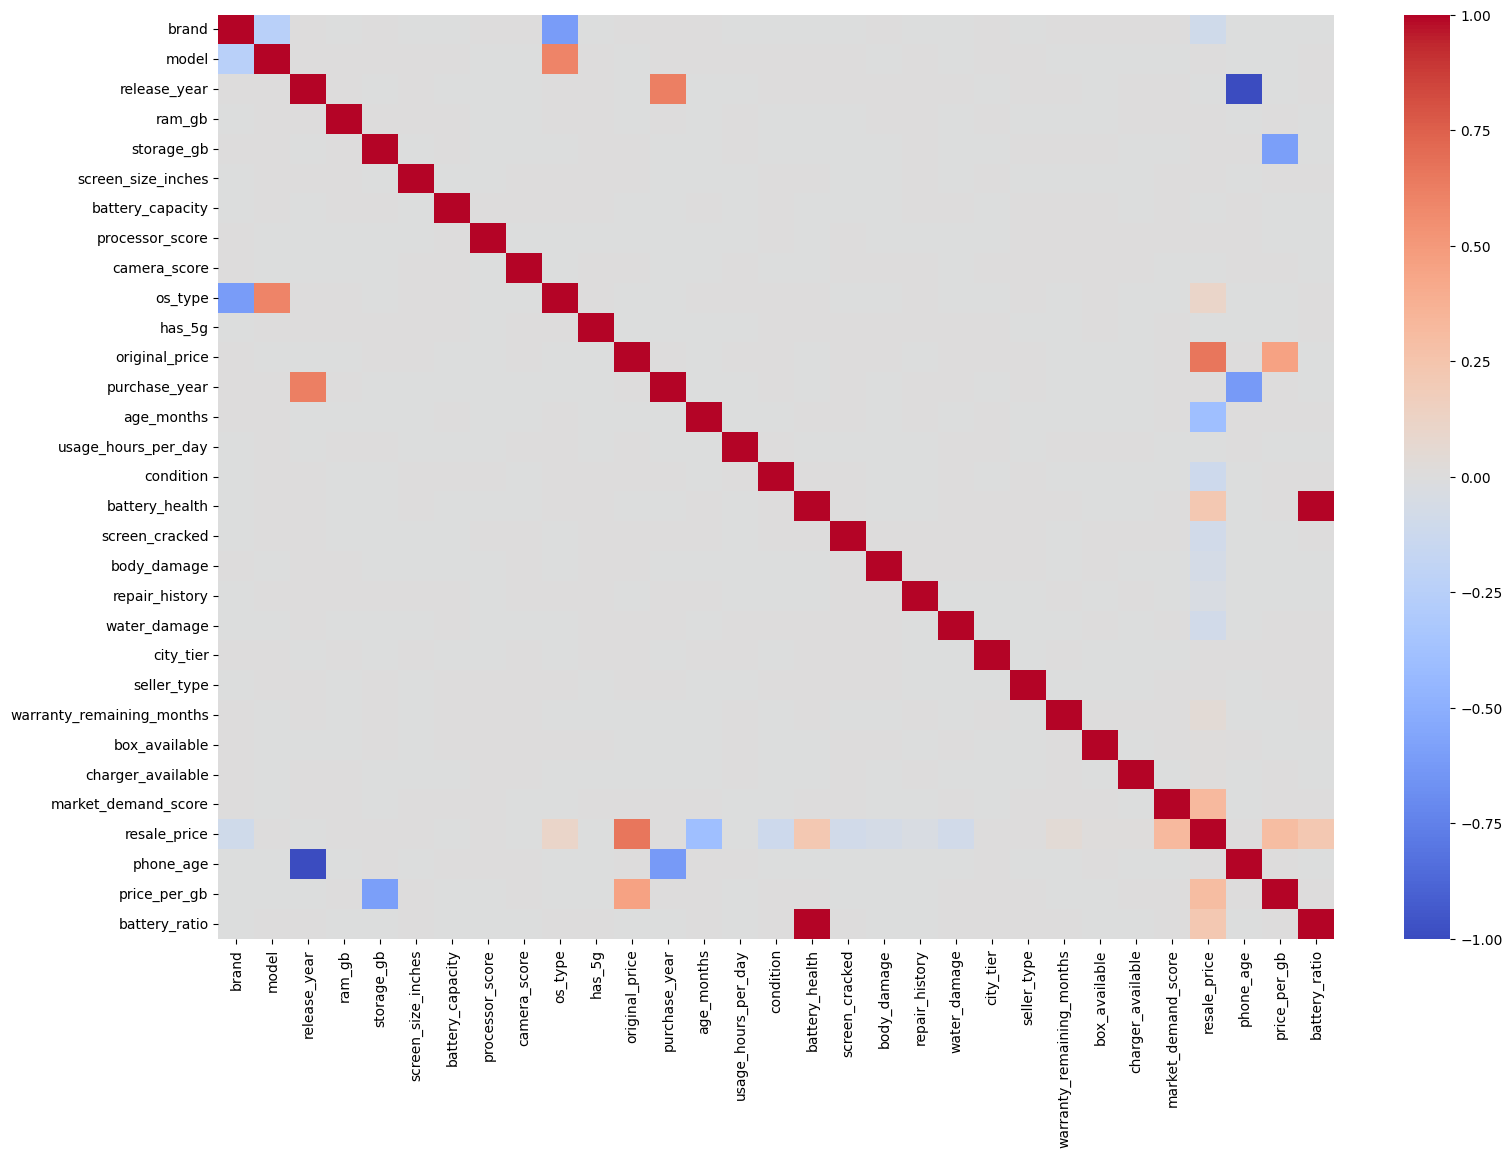

In [ ]:
plt.figure(figsize=(18,12))

sns.heatmap(df.corr(),
            cmap="coolwarm",
            annot=False)

plt.show()

In [ ]:
X = df.drop("resale_price", axis=1)

y = df["resale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

In [ ]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

In [ ]:
xgb = XGBRegressor(random_state=42)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

In [ ]:
lgb = LGBMRegressor(random_state=42)

lgb.fit(X_train, y_train)

pred_lgb = lgb.predict(X_test)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.120338 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1497
[LightGBM] [Info] Number of data points in the train set: 800000, number of used features: 30
[LightGBM] [Info] Start training from score 22584.041119
